In [4]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import os
# os.chdir('..')
get_ipython().run_line_magic('matplotlib', 'inline')
import json
import glob

In [5]:
#set the path/data location
data = pd.read_csv("data/data_selected_new_existing.csv")

In [6]:
data.columns

Index(['ECD', 'child_sex', 'child_age', 'birth_order',
       'preceding_birth_interval', 'baby_postnatal_check', 'birth_wt',
       'supplemented_VitA', 'drug_intestinal_parasite', 'EaChDisease', 'cough',
       'diarrhea', 'stunted', 'underwt', 'wasted', 'overwt', 'current_age',
       'education_level', 'fathers_edu', 'marital_status', 'number_ANC',
       'working_status', 'wealth_Index', 'No_HH_Member', 'health_insurance',
       'distance_to_facility', 'water_source', 'sanitation_facility',
       'HH_head_sex', 'media_exposure', 'internet_use',
       'frequency_internet_use', 'residence'],
      dtype='str')

In [8]:
#since we updated the anconda, the numpy gotta be downgraded to function. Therefore:# pip install "numpy<2"

In [7]:
#dropping a variable with missing >=40%#
data= data.drop('birth_wt', axis=1)
data= data.drop('baby_postnatal_check', axis=1)
data= data.drop('stunted', axis=1)
data= data.drop('wasted', axis=1)
data= data.drop('underwt', axis=1)
data= data.drop('overwt', axis=1)
data= data.drop('number_ANC', axis=1)
data= data.drop('fathers_edu', axis=1)
data= data.drop('health_insurance', axis=1)
data= data.drop('frequency_internet_use', axis=1)
#Extra variables with missing values
data= data.drop('water_source', axis=1)
data= data.drop('drug_intestinal_parasite', axis=1)
data= data.drop('supplemented_VitA', axis=1)

In [8]:
from sklearn.preprocessing import LabelEncoder 

In [9]:
# Convert categorical data to numerical data using LabelEncoder 
le = LabelEncoder()
data['child_sex'] = le.fit_transform(data['child_sex'])
data['child_age'] = le.fit_transform(data['child_age'])
data['residence'] = le.fit_transform(data['residence'])
# data['supplemented_VitA'] = le.fit_transform(data['supplemented_VitA'])
# data['drug_intestinal_parasite'] = le.fit_transform(data['drug_intestinal_parasite'])
data['HH_head_sex'] = le.fit_transform(data['HH_head_sex'])
data['birth_order'] = le.fit_transform(data['birth_order'])
data['preceding_birth_interval'] = le.fit_transform(data['preceding_birth_interval'])
data['EaChDisease'] = le.fit_transform(data['EaChDisease'])
data['current_age'] = le.fit_transform(data['current_age'])
data['education_level'] = le.fit_transform(data['education_level'])
data['marital_status'] = le.fit_transform(data['marital_status'])
data['working_status'] = le.fit_transform(data['working_status'])
data['wealth_Index'] = le.fit_transform(data['wealth_Index'])
data['distance_to_facility'] = le.fit_transform(data['distance_to_facility'])
data['media_exposure'] = le.fit_transform(data['media_exposure'])
data['No_HH_Member'] = le.fit_transform(data['No_HH_Member'])
data['diarrhea'] = le.fit_transform(data['diarrhea'])
data['cough'] = le.fit_transform(data['cough'])
data['internet_use'] = le.fit_transform(data['internet_use'])
data['sanitation_facility'] = le.fit_transform(data['sanitation_facility'])

In [10]:
#define the independent and outcome variables
X= data.drop(["ECD"], axis = 1)
Y= data["ECD"]

In [11]:
# Train/Test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [12]:
#instal imblearn
get_ipython().system('pip install imblearn')


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


<Axes: xlabel='ECD', ylabel='count'>

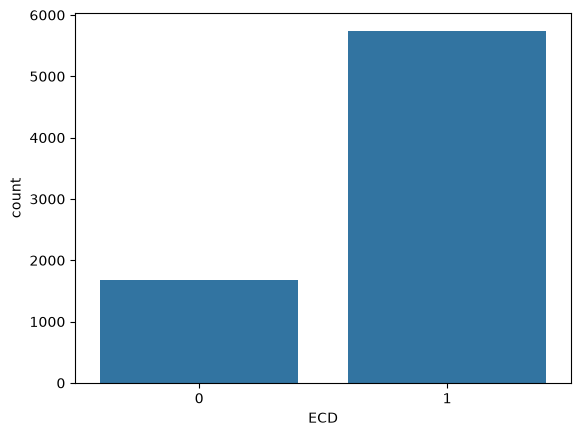

In [13]:
#see the imbalance
sns.countplot(x ='ECD', data=data) 

In [14]:
# Baseline Model training with the raw dataset
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators = 500, max_depth = 4, max_features = 3, bootstrap = True, random_state = 22).fit(x_train, y_train)

In [15]:
from sklearn.metrics import classification_report
baseline_prediction = clf.predict(x_test)

In [16]:
#Grid search (done already) and Train RF
from sklearn.ensemble import RandomForestClassifier
rfc_tuned = RandomForestClassifier(criterion = 'gini', max_depth = 4, max_features= 'sqrt', min_samples_leaf= 1, min_samples_split= 10, n_estimators = 50, random_state = 42)
rfc_tuned.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [17]:
# Check the model performance
print(classification_report(y_test, baseline_prediction))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       336
           1       0.77      1.00      0.87      1147

    accuracy                           0.77      1483
   macro avg       0.39      0.50      0.44      1483
weighted avg       0.60      0.77      0.67      1483



/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

In [18]:
#we will try 3 methods and choose the best one
#option one- Random oversampler/ Randomly over sample the minority class
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros= ros.fit_resample(x_train, y_train)

In [19]:
# Check the number of records after over sampling
from collections import Counter
print(sorted(Counter(y_train_ros).items()))

[(0, 4593), (1, 4593)]


In [20]:
#fit the resampled data
ros_model = clf.fit(X_train_ros, y_train_ros)
ros_prediction = ros_model.predict(x_test)

In [21]:
# Check the model performance
print(classification_report(y_test, ros_prediction)) 

              precision    recall  f1-score   support

           0       0.34      0.51      0.40       336
           1       0.83      0.70      0.76      1147

    accuracy                           0.66      1483
   macro avg       0.58      0.61      0.58      1483
weighted avg       0.72      0.66      0.68      1483



In [22]:
print("X_train_ros shape:", X_train_ros.shape)
print("x_test shape:", x_test.shape)

X_train_ros shape: (9186, 19)
x_test shape: (1483, 19)


In [23]:
# SMOTE: Randomly over sample the minority class
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote= smote.fit_resample(x_train, y_train)

In [24]:
# Check the number of records after over sampling
print(sorted(Counter(y_train_smote).items()))

[(0, 4593), (1, 4593)]


In [25]:
smote_model = clf.fit(X_train_smote, y_train_smote)
smote_prediction = smote_model.predict(x_test)

In [26]:
# Check the model performance
print(classification_report(y_test, smote_prediction)) 

              precision    recall  f1-score   support

           0       0.30      0.56      0.39       336
           1       0.83      0.62      0.71      1147

    accuracy                           0.60      1483
   macro avg       0.56      0.59      0.55      1483
weighted avg       0.71      0.60      0.64      1483



In [27]:
#now try nearmiss undersampling
from imblearn.under_sampling import NearMiss
nearmiss = NearMiss()
X_train_nearmiss, y_train_nearmiss = nearmiss.fit_resample(x_train, y_train)

In [28]:
# Check the number of records after under sampling
print(sorted(Counter(y_train_nearmiss).items()))

[(0, 1335), (1, 1335)]


In [29]:
nearmiss_model = clf.fit(X_train_nearmiss, y_train_nearmiss)
nearmiss_prediction = nearmiss_model.predict(x_test)

In [30]:
# Check the model performance
print(classification_report(y_test, nearmiss_prediction)) 

              precision    recall  f1-score   support

           0       0.25      0.63      0.35       336
           1       0.80      0.44      0.56      1147

    accuracy                           0.48      1483
   macro avg       0.52      0.53      0.46      1483
weighted avg       0.67      0.48      0.52      1483



In [31]:
# Randomly under sample the majority class
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus= rus.fit_resample(x_train, y_train)

In [32]:
# Check the number of records after under sampling
print(sorted(Counter(y_train_rus).items()))

[(0, 1335), (1, 1335)]


In [33]:
rus_model = clf.fit(X_train_rus, y_train_rus)
rus_prediction = rus_model.predict(x_test)

In [34]:
# Check the model performance
print(classification_report(y_test, rus_prediction))

              precision    recall  f1-score   support

           0       0.34      0.56      0.42       336
           1       0.84      0.67      0.75      1147

    accuracy                           0.65      1483
   macro avg       0.59      0.62      0.58      1483
weighted avg       0.73      0.65      0.67      1483

